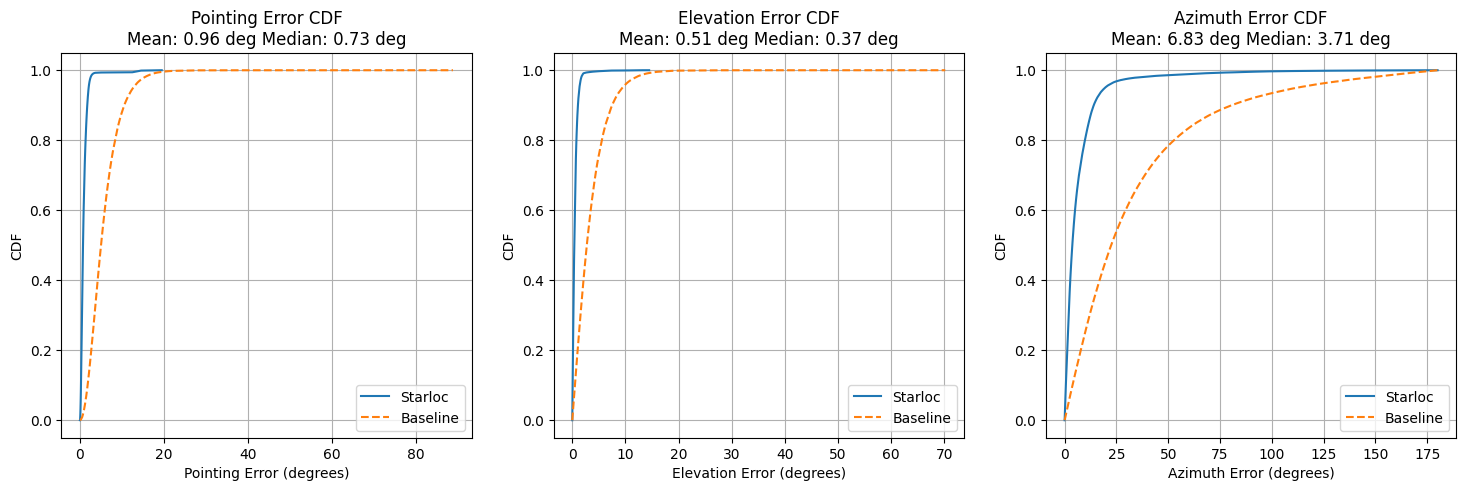

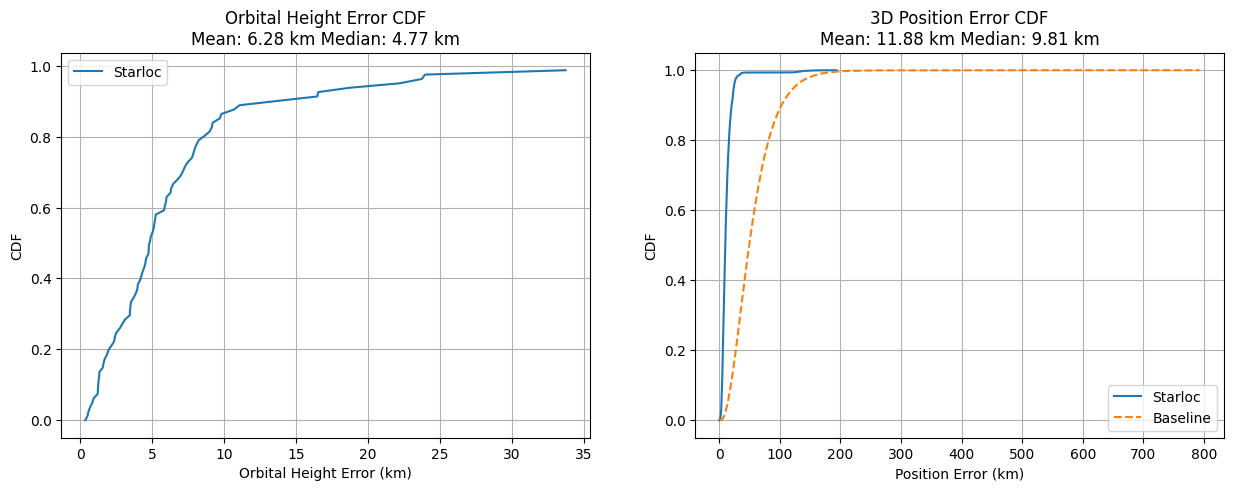

In [2]:
res_folder = 'results/'
# read all json files and aggregate the results
import glob
import json
import os
import matplotlib.pyplot as plt
import numpy as np

# Set default font sizes for all plot text to 12
okabe_ito = ["#000000", "#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2", "#D55E00", "#CC79A7"]


all_files = glob.glob(os.path.join(res_folder, '*.json'))
elevation_all = np.array([])
azimuth_all = np.array([])
elevation_baseline_all = np.array([])
azimuth_baseline_all = np.array([])
elevation_gt_all = np.array([])
azimuth_gt_all = np.array([])
pointing_err_all = np.array([])
pointing_err_baseline_all = np.array([])
orbit_height_err_all = np.array([])
pos_err_all = np.array([])
pos_err_baseline_all = np.array([])

for file in all_files:
    with open(file, 'r') as f:
        data = json.load(f)
    for sat_idx in data:
        if sat_idx == '__starloc_config__':
            continue
        el = np.array(data[sat_idx]['el_origphase'])
        az = np.array(data[sat_idx]['az_origphase'])
        el_baseline = np.array(data[sat_idx]['el_baseline_origphase'])
        az_baseline = np.array(data[sat_idx]['az_baseline_origphase'])
        el_gt = np.array(data[sat_idx]['el_gt_origphase'])
        az_gt = np.array(data[sat_idx]['az_gt_origphase'])
        ranges_gt = np.array(data[sat_idx]['range_gt_origphase'])
        elevation_all = np.concatenate((elevation_all, el))
        azimuth_all = np.concatenate((azimuth_all, az))
        elevation_baseline_all = np.concatenate((elevation_baseline_all, el_baseline))
        azimuth_baseline_all = np.concatenate((azimuth_baseline_all, az_baseline))
        elevation_gt_all = np.concatenate((elevation_gt_all, el_gt))
        azimuth_gt_all = np.concatenate((azimuth_gt_all, az_gt))
        pointing_err_all = np.concatenate((pointing_err_all, np.array(data[sat_idx]['pointing_err_origphase'])))
        pointing_err_baseline_all = np.concatenate((pointing_err_baseline_all, np.array(data[sat_idx]['pointing_err_baseline_origphase'])))
        orbit_height_est = np.array(data[sat_idx]['orbit_height_est'])
        orbit_height_err_all = np.append(orbit_height_err_all, orbit_height_est - data[sat_idx]['orbit_height_gt'])
        range_est = orbit_height_est / np.sin(el)
        # R_E = 6371000 # earth radius in meters
        # range_est = -R_E * np.sin(el) + np.sqrt((R_E * np.sin(el))**2 + 2 * R_E * orbit_height_est + orbit_height_est**2)

        pos_gt = np.array([ranges_gt * np.cos(el_gt) * np.cos(az_gt),
                           ranges_gt * np.cos(el_gt) * np.sin(az_gt),
                           ranges_gt * np.sin(el_gt)]).T
        pos_est = np.array([range_est * np.cos(el) * np.cos(az),
                            range_est * np.cos(el) * np.sin(az),
                            range_est * np.sin(el)]).T
        pos_est_baseline = np.array([range_est * np.cos(el_baseline) * np.cos(az_baseline),
                            range_est * np.cos(el_baseline) * np.sin(az_baseline),
                            range_est * np.sin(el_baseline)]).T
        pos_err = np.linalg.norm(pos_est - pos_gt, axis=1)
        pos_err_all = np.concatenate((pos_err_all, pos_err))
        pos_err_baseline = np.linalg.norm(pos_est_baseline - pos_gt, axis=1)
        pos_err_baseline_all = np.concatenate((pos_err_baseline_all, pos_err_baseline))

elevation_err = np.rad2deg(elevation_all - elevation_gt_all)
azimuth_err = np.rad2deg(azimuth_all - azimuth_gt_all)
azimuth_err_baseline = np.rad2deg(azimuth_baseline_all - azimuth_gt_all)
elevation_err_baseline = np.rad2deg(elevation_baseline_all - elevation_gt_all)

# wrap azimuth error to -180 to 180
azimuth_err = (azimuth_err + 180) % 360 - 180
azimuth_err_baseline = (azimuth_err_baseline + 180) % 360 - 180
# take absolute value
elevation_err = np.abs(elevation_err)
azimuth_err = np.abs(azimuth_err)
elevation_err_baseline = np.abs(elevation_err_baseline)
azimuth_err_baseline = np.abs(azimuth_err_baseline)
# plot cdf of elevation and azimuth error
%matplotlib inline
plt.figure(figsize=(18,5))
plt.subplot(1,3,1)
plt.title('Pointing Error CDF\nMean: {:.2f} deg Median: {:.2f} deg'.format(np.rad2deg(np.mean(pointing_err_all)), np.rad2deg(np.median(pointing_err_all))))
plt.xlabel('Pointing Error (degrees)')
plt.ylabel('CDF')
sorted_err = np.sort(np.rad2deg(pointing_err_all))
cdf = np.arange(len(sorted_err)) / float(len(sorted_err))
sorted_err_baseline = np.sort(np.rad2deg(pointing_err_baseline_all))
cdf_baseline = np.arange(len(sorted_err_baseline)) / float(len(sorted_err_baseline))
plt.plot(sorted_err, cdf, label='Starloc')
plt.plot(sorted_err_baseline, cdf_baseline, label='Baseline', linestyle='--')
plt.grid()
plt.legend()

plt.subplot(1,3,2)
plt.title('Elevation Error CDF\nMean: {:.2f} deg Median: {:.2f} deg'.format(np.mean(elevation_err), np.median(elevation_err)))
plt.xlabel('Elevation Error (degrees)')
plt.ylabel('CDF')
sorted_err = np.sort(elevation_err)
cdf = np.arange(len(sorted_err)) / float(len(sorted_err))
sorted_err_baseline = np.sort(elevation_err_baseline)
cdf_baseline = np.arange(len(sorted_err_baseline)) / float(len(sorted_err_baseline))
plt.plot(sorted_err, cdf, label='Starloc')
plt.plot(sorted_err_baseline, cdf_baseline, label='Baseline', linestyle='--')
plt.grid()
plt.legend()
plt.subplot(1,3,3)
plt.title('Azimuth Error CDF\nMean: {:.2f} deg Median: {:.2f} deg'.format(np.mean(azimuth_err), np.median(azimuth_err)))
plt.xlabel('Azimuth Error (degrees)')
plt.ylabel('CDF')
sorted_err = np.sort(azimuth_err)
cdf = np.arange(len(sorted_err)) / float(len(sorted_err))
sorted_err_baseline = np.sort(azimuth_err_baseline)
cdf_baseline = np.arange(len(sorted_err_baseline)) / float(len(sorted_err_baseline))
plt.plot(sorted_err, cdf, label='Starloc')
plt.plot(sorted_err_baseline, cdf_baseline, label='Baseline', linestyle='--')
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(15,5))
plt.subplot(1,2,1)
plt.title("Orbital Height Error CDF\nMean: {:.2f} km Median: {:.2f} km".format(np.mean(np.abs(orbit_height_err_all))/1e3, np.median(np.abs(orbit_height_err_all))/1e3))
plt.xlabel("Orbital Height Error (km)")
plt.ylabel("CDF")
orbit_height_err_all = np.abs(orbit_height_err_all)
sorted_err = np.sort(orbit_height_err_all/1e3)
cdf = np.arange(len(sorted_err)) / float(len(sorted_err))
plt.plot(sorted_err, cdf, label='Starloc')
plt.grid()
plt.legend()

plt.subplot(1,2,2)
plt.title("3D Position Error CDF\nMean: {:.2f} km Median: {:.2f} km".format(np.mean(pos_err_all)/1e3, np.median(pos_err_all)/1e3))
plt.xlabel("Position Error (km)")
plt.ylabel("CDF")
pos_err_all = np.abs(pos_err_all)
pos_err_baseline_all = np.abs(pos_err_baseline_all)
sorted_err = np.sort(pos_err_all/1e3)
sorted_err_baseline = np.sort(pos_err_baseline_all/1e3)
cdf = np.arange(len(sorted_err)) / float(len(sorted_err))
cdf_baseline = np.arange(len(sorted_err_baseline)) / float(len(sorted_err_baseline))
plt.plot(sorted_err, cdf, label='Starloc')
plt.plot(sorted_err_baseline, cdf_baseline, label='Baseline', linestyle='--')
plt.grid()
plt.legend()
plt.show()

Median 3D angle err:  0.732781865026958
95-th percentile angle error 1.7444881285017422
Median range err:  4.772477512654033
95-th percentile range error 11.069034313125186
Median pos err:  9.810069649033169


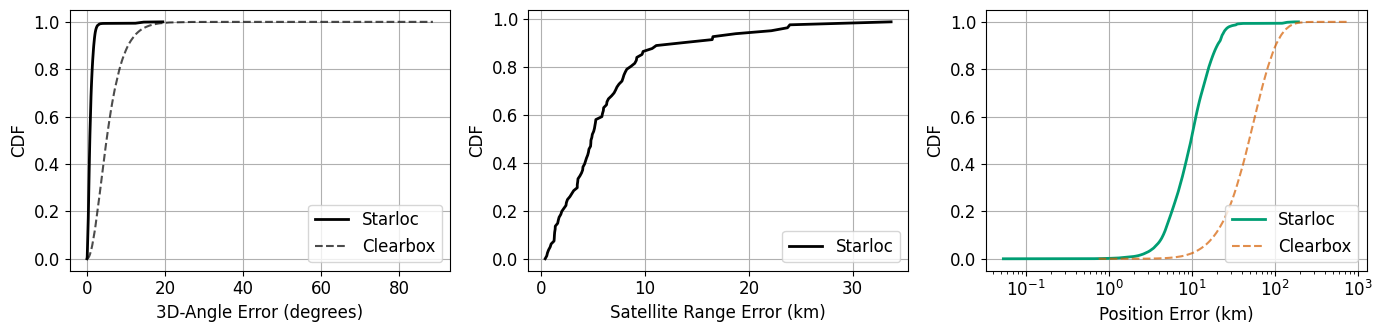

In [3]:
from matplotlib import legend


plt.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 12,
    'axes.labelsize': 12,
    'legend.fontsize': 12,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12, 
    'legend.loc':'lower right'
})
plt.figure(figsize=(14,3.5))
plt.subplot(1,3,1)
# plt.title('Pointing Error CDF\nMean: {:.2f} deg Median: {:.2f} deg'.format(np.rad2deg(np.mean(pointing_err_all)), np.rad2deg(np.median(pointing_err_all))))
plt.xlabel('3D-Angle Error (degrees)')
plt.ylabel('CDF')

sorted_err = np.sort(np.rad2deg(pointing_err_all)[np.isnan(np.rad2deg(pointing_err_all))==False])
cdf = np.arange(len(sorted_err)) / float(len(sorted_err))
sorted_err_baseline = np.sort(np.rad2deg(pointing_err_baseline_all)[np.isnan(np.rad2deg(pointing_err_baseline_all))==False])
cdf_baseline = np.arange(len(sorted_err_baseline)) / float(len(sorted_err_baseline))

plt.plot(sorted_err, cdf, label='Starloc', color=okabe_ito[0], linewidth=2)
plt.plot(sorted_err_baseline, cdf_baseline, label='Clearbox', linestyle='--', color=okabe_ito[0], alpha=0.7)
plt.grid()
plt.legend()
print('Median 3D angle err: ', np.median(sorted_err))
print('95-th percentile angle error', np.percentile(sorted_err, 90))


plt.subplot(1,3,2)
# plt.title("Orbital Height Error CDF\nMean: {:.2f} km Median: {:.2f} km".format(np.mean(np.abs(orbit_height_err_all))/1e3, np.median(np.abs(orbit_height_err_all))/1e3))
plt.xlabel("Satellite Range Error (km)")
plt.ylabel("CDF")
orbit_height_err_all = np.abs(orbit_height_err_all)
sorted_err = np.sort(orbit_height_err_all/1e3)
cdf = np.arange(len(sorted_err)) / float(len(sorted_err))
plt.plot(sorted_err, cdf, label='Starloc', color=okabe_ito[0], linewidth=2)
plt.grid()
plt.legend()
print('Median range err: ', np.median(sorted_err))
print('95-th percentile range error', np.percentile(sorted_err, 90))


plt.subplot(1,3,3)
# plt.title("3D Position Error CDF\nMean: {:.2f} km Median: {:.2f} km".format(np.mean(pos_err_all)/1e3, np.median(pos_err_all)/1e3))
plt.xlabel("Position Error (km)")
plt.ylabel("CDF")
pos_err_all = np.abs(pos_err_all)
pos_err_baseline_all = np.abs(pos_err_baseline_all)
sorted_err = np.sort(pos_err_all/1e3)
sorted_err_baseline = np.sort(pos_err_baseline_all/1e3)
cdf = np.arange(len(sorted_err)) / float(len(sorted_err))
cdf_baseline = np.arange(len(sorted_err_baseline)) / float(len(sorted_err_baseline))
plt.plot(sorted_err, cdf, label='Starloc', color=okabe_ito[3], linewidth=2)
plt.plot(sorted_err_baseline, cdf_baseline, label='Clearbox', linestyle='--', color=okabe_ito[6], alpha=0.7)
plt.xscale('log')
plt.grid()
plt.legend()
plt.tight_layout()
print('Median pos err: ', np.median(sorted_err))
# save figure
# plt.savefig('pointing_height_position_error_cdf.pdf', dpi=300)



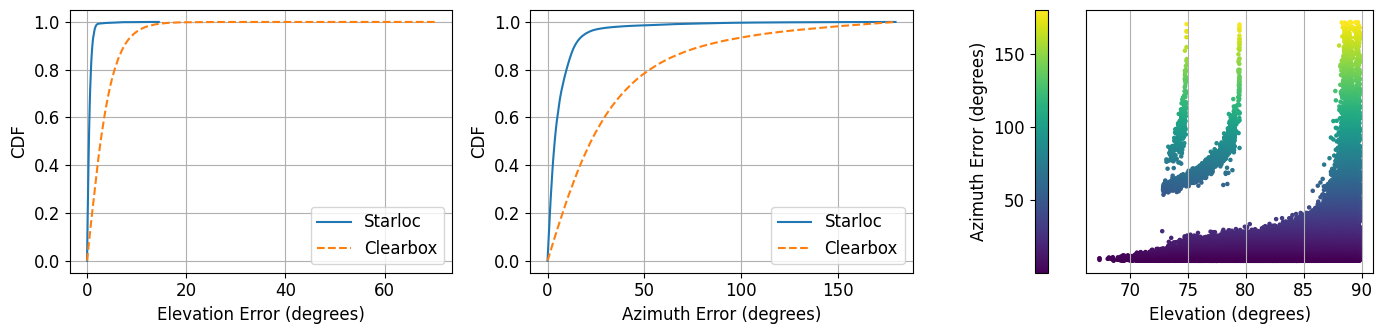

In [4]:
# figure for azimuth error cdf, elevation error cdf and azimuth vs elevation error
plt.figure(figsize=(14,3.5))
plt.subplot(1,3,1)  
plt.xlabel('Elevation Error (degrees)')
plt.ylabel('CDF')
sorted_err = np.sort(elevation_err)
cdf = np.arange(len(sorted_err)) / float(len(sorted_err))
sorted_err_baseline = np.sort(elevation_err_baseline)
cdf_baseline = np.arange(len(sorted_err_baseline)) / float(len(sorted_err_baseline))
plt.plot(sorted_err, cdf, label='Starloc')
plt.plot(sorted_err_baseline, cdf_baseline, label='Clearbox', linestyle='--')
plt.grid()
plt.legend()


plt.subplot(1,3,2)
plt.xlabel('Azimuth Error (degrees)')
plt.ylabel('CDF')
sorted_err = np.sort(azimuth_err)
cdf = np.arange(len(sorted_err)) / float(len(sorted_err))
sorted_err_baseline = np.sort(azimuth_err_baseline)
cdf_baseline = np.arange(len(sorted_err_baseline)) / float(len(sorted_err_baseline))
plt.plot(sorted_err, cdf, label='Starloc')
plt.plot(sorted_err_baseline, cdf_baseline, label='Clearbox', linestyle='--')
plt.legend()
plt.grid()

plt.subplot(1,3,3)
# sort el_gt array and use the sorted indices to sort azimuth_err
sorted_indices = np.argsort(elevation_gt_all)
elevation_gt_all_sorted = elevation_gt_all[sorted_indices]
# get indices where elevation_gt_all_sorted is not nan
valid_indices = np.isnan(elevation_gt_all_sorted) == False
elevation_gt_all_sorted = elevation_gt_all_sorted[valid_indices]
azimuth_err_sorted = azimuth_err[sorted_indices]
azimuth_err_sorted = azimuth_err_sorted[valid_indices]
# now plot distribution of azimuth error vs elevation gt to show that az error is large at high elevations
heatmap_data = np.vstack((np.rad2deg(elevation_gt_all_sorted), azimuth_err_sorted)).T
# i want to show that azimuth error is large at high elevations so value of azimuth error should be represented by color intensity
plt.scatter(np.rad2deg(elevation_gt_all_sorted), azimuth_err_sorted, c=azimuth_err_sorted, cmap='viridis', s=5)
# colorbar position on he left side
cbar = plt.colorbar(location='left')
cbar.set_label('Azimuth Error (degrees)')
plt.xlabel('Elevation (degrees)')
# plt.ylabel('Azimuth Error (degrees)')
# remove yticks
plt.yticks([])
plt.grid()
plt.tight_layout()
# plt.savefig('az_el_error_cdf_scatter.png', dpi=300)